In [18]:
import pandas as pd
import numpy as np
import sys
import os
import matplotlib.pyplot as plt

In [2]:
# Load the historical flights dataset
print("Loading historical flights dataset...")
data_path = "/home/kristsey/AvinorHackathon/data/avinor_data/historical_flights.csv"

# Load data
df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")
print("\nDataset Info:")
print(df.info())
print("\nFirst few rows:")
print(df.head())

Loading historical flights dataset...
Dataset shape: (410442, 11)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410442 entries, 0 to 410441
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   flight_id          410442 non-null  object
 1   dep_airport        410442 non-null  object
 2   dep_airport_group  232968 non-null  object
 3   arr_airport        410442 non-null  object
 4   arr_airport_group  231669 non-null  object
 5   service_type       410336 non-null  object
 6   std                410442 non-null  object
 7   sta                410442 non-null  object
 8   cancelled          410442 non-null  int64 
 9   atd                394327 non-null  object
 10  ata                393576 non-null  object
dtypes: int64(1), object(10)
memory usage: 34.4+ MB
None

First few rows:
  flight_id dep_airport dep_airport_group arr_airport arr_airport_group  \
0     WF149         HOV            

In [4]:
# Load the october schedule dataset
print("Testing for unscheduled service types")
scheduled_data_path = (
    "/home/kristsey/AvinorHackathon/data/avinor_data/schedule_oct2025.csv"
)

# Load data
scheduled_data_october = pd.read_csv(scheduled_data_path)


print(f"Dataset shape: {df.shape}")
print("\nDataset Info:")
print(df.info())
print("\nFirst few rows:")
print(df.isna().sum())

historical_flight_service_types = df["service_type"].unique()
scheduled_flight_service_types = scheduled_data_october["service_type"].unique()
print("Historical flight service types:", historical_flight_service_types)
print("Scheduled flight service types:", scheduled_flight_service_types)
unscheduled_service_types = set(scheduled_flight_service_types) - set(
    historical_flight_service_types
)
print("Unscheduled service types in scheduled data:", unscheduled_service_types)
# Remove rows with missing actual departure or arrival times

Testing for unscheduled service types
Dataset shape: (410442, 11)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410442 entries, 0 to 410441
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   flight_id          410442 non-null  object
 1   dep_airport        410442 non-null  object
 2   dep_airport_group  232968 non-null  object
 3   arr_airport        410442 non-null  object
 4   arr_airport_group  231669 non-null  object
 5   service_type       410336 non-null  object
 6   std                410442 non-null  object
 7   sta                410442 non-null  object
 8   cancelled          410442 non-null  int64 
 9   atd                394327 non-null  object
 10  ata                393576 non-null  object
dtypes: int64(1), object(10)
memory usage: 34.4+ MB
None

First few rows:
flight_id                 0
dep_airport               0
dep_airport_group    177474
arr_airport               

In [11]:
# Add the parent directory to the Python path so we can import from src
parent_dir = os.path.dirname(os.path.dirname(os.path.abspath("avinorhackathon")))
if parent_dir not in sys.path:
    sys.path.append(parent_dir)

print(sys.path)

# Now we can import from src
from src.preprocessing import DataPreprocessor

data_preprocessor = DataPreprocessor()
df_processed = data_preprocessor.process_hist_flights(df)

na_airport_group_data = df_processed[
    df_processed["arr_airport_group"].isna() | df_processed["dep_airport_group"].isna()
]

print(na_airport_group_data.head())


# Remove rows with missing actual departure or arrival times
df_schedule = df_processed.drop(["atd", "ata"], axis=1).dropna()
df_actual = df_processed.drop(["std", "sta"], axis=1).dropna()
df_actual = df_actual.rename(
    columns={"atd": "std", "ata": "sta"}
).dropna()  # Rename actual times to scheduled times for actual dataset


print(f"Dataset shape after removing actual values", df_schedule.isna().sum())

['/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload', '', '/lhome/kristsey/AvinorHackathon/.venv/lib/python3.12/site-packages', '/lhome/kristsey/AvinorHackathon']
Missing values after processing:
flight_id                 0
dep_airport               0
dep_airport_group    169367
arr_airport               0
arr_airport_group    169919
service_type              0
std                       0
sta                       0
atd                       0
ata                       0
dtype: int64
    flight_id dep_airport dep_airport_group arr_airport arr_airport_group  \
362    WF7101         SKN               NaN         MJF                 D   
363    WF8102         MJF                 D         BOO               NaN   
364     WF743         MJF                 D         OSL               NaN   
365    WF7025         OSL               NaN         MJF                 D   
366    SK4516         OSL               NaN         MOL                 B   

    service_type 

In [6]:
def create_concurrency_binary_target(df):
    """
    Create a binary target indicating whether concurrency > 0
    """
    df = df.copy()
    df["is_concurrency"] = (df["concurrency"] > 0).astype(int)
    return df

In [ ]:
def compute_scheduled_concurrency(df, include_features=False):
    """ "
    For every airport group, and hour from first scheduled time to last scheduled time, count the concurrency

    Concurrency is defined as the number of times an airport group has an overlapping scheduled departure or arrival within a certain timeframe

    The timeframe is defined as 16 minutes before to 5 minutes after a landing, or 15 minutes before to 8 inutes after takeoff
    """
    scheduled_df = df.copy()
    concurrency_records = []

    # Convert scheduled times to datetime
    scheduled_df["std"] = pd.to_datetime(scheduled_df["std"])
    scheduled_df["sta"] = pd.to_datetime(scheduled_df["sta"])

    # Get the range of hours to consider
    min_time = min(scheduled_df["std"].min(), scheduled_df["sta"].min()).floor("H")
    max_time = max(scheduled_df["std"].max(), scheduled_df["sta"].max()).ceil("H")

    # Create a time range with hourly frequency
    time_range = pd.date_range(start=min_time, end=max_time, freq="H")

    # Iterate over each airport group
    airport_groups = (
        pd.concat(
            [scheduled_df["dep_airport_group"], scheduled_df["arr_airport_group"]]
        )
        .dropna()
        .unique()
    )

    dep_scheduled_df = scheduled_df[scheduled_df["dep_airport_group"].notna().copy()]
    arr_scheduled_df = scheduled_df[scheduled_df["arr_airport_group"].notna().copy()]

    dep_scheduled_df["time_window_start"] = dep_scheduled_df["std"] - pd.Timedelta(
        minutes=15
    )
    dep_scheduled_df["time_window_end"] = dep_scheduled_df["std"] + pd.Timedelta(
        minutes=8
    )

    arr_scheduled_df["time_window_start"] = arr_scheduled_df["sta"] - pd.Timedelta(
        minutes=16
    )
    arr_scheduled_df["time_window_end"] = arr_scheduled_df["sta"] + pd.Timedelta(
        minutes=5
    )

    dep_scheduled_df = dep_scheduled_df.rename(
        columns={"dep_airport_group": "airport_group"}
    ).drop(columns=["arr_airport_group"])
    arr_scheduled_df = arr_scheduled_df.rename(
        columns={"arr_airport_group": "airport_group"}
    ).drop(columns=["dep_airport_group"])

    dep_arr_scheduled_df = pd.concat([dep_scheduled_df, arr_scheduled_df])

    concurrency_df = pd.DataFrame(
        columns=["airport_group", "date", "hour", "concurrency"]
    )
    concurrency_records = []

    # start_time = dep_arr_scheduled_df["std"].min().floor("m")
    # end_time = dep_arr_scheduled_df["sta"].max().ceil("m")
    start_time = (
        dep_arr_scheduled_df["std"].min().floor("D").replace(day=1)
    )  # Start of month
    end_time = (
        dep_arr_scheduled_df["sta"].max().ceil("D").replace(day=1)
        + pd.DateOffset(months=1)
        - pd.Timedelta(days=1)
    ).ceil(
        "D"
    )  # End of month

    time_index = pd.date_range(start=start_time, end=end_time, freq="h")

    for airport_group in airport_groups:
        print(f"Processing airport group: {airport_group}")
        # iterate over time index
        for current_time in time_index:
            # Define the current hour window
            next_hour = current_time + pd.Timedelta(hours=1)

            # Get all flights for this airport group
            group_flights = dep_arr_scheduled_df[
                dep_arr_scheduled_df["airport_group"] == airport_group
            ]

            # Find flights whose time windows overlap with the current hour
            # A time window overlaps with the current hour if:
            # - The window starts before the hour ends AND
            # - The window ends after the hour starts
            flights_in_window = group_flights[
                (group_flights["time_window_start"] < next_hour)
                & (group_flights["time_window_end"] > current_time)
            ]

            # Now calculate the actual concurrency: count overlapping time windows between flights
            concurrency_count = 0
            concurrency_windows = []

            # For each flight in the window, count how many other flights overlap with it
            for i in range(len(flights_in_window)):
                flight_i = flights_in_window.iloc[i]
                for j in range(i + 1, len(flights_in_window)):
                    flight_j = flights_in_window.iloc[j]

                    # Check if time windows of flight_i and flight_j overlap
                    # Two time windows overlap if:
                    # - flight_i starts before flight_j ends AND
                    # - flight_j starts before flight_i ends
                    if (
                        flight_i["time_window_start"] < flight_j["time_window_end"]
                        and flight_j["time_window_start"] < flight_i["time_window_end"]
                    ):
                        concurrency_windows.append(
                            (
                                max(
                                    flight_i["time_window_start"],
                                    flight_j["time_window_start"],
                                ),
                                min(
                                    flight_i["time_window_end"],
                                    flight_j["time_window_end"],
                                ),
                            )
                        )
            # Merge overlapping concurrency windows
            if concurrency_windows:
                # Sort windows by start time
                concurrency_windows.sort(key=lambda x: x[0])
                merged_windows = [concurrency_windows[0]]

                for current_start, current_end in concurrency_windows[1:]:
                    last_start, last_end = merged_windows[-1]

                    if current_start <= last_end:  # Overlap
                        merged_windows[-1] = (last_start, max(last_end, current_end))
                    else:
                        merged_windows.append((current_start, current_end))

                concurrency_count = len(merged_windows)
            else:
                concurrency_count = 0

            overlapping_time = (
                sum((end - start).total_seconds() / 60 for start, end in merged_windows)
                if concurrency_count > 0
                else 0
            )

            if include_features:
                concurrency_records.append(
                    {
                        "airport_group": airport_group,
                        "date": current_time.date(),
                        "hour": current_time.hour,
                        "concurrency": concurrency_count,
                        "number_of_flights": len(flights_in_window),
                        "overlapping_time_minutes": overlapping_time,
                    }
                )
            else:
                concurrency_records.append(
                    {
                        "airport_group": airport_group,
                        "date": current_time.date(),
                        "hour": current_time.hour,
                        "concurrency": concurrency_count,
                    }
                )

    # Convert records to DataFrame
    concurrency_df = pd.DataFrame(concurrency_records)
    return concurrency_df

In [6]:
scheduled_concurrency_oct = compute_scheduled_concurrency(
    scheduled_data_october, include_features=True
)
scheduled_concurrency_oct = scheduled_concurrency_oct.sort_values(
    by=["date", "hour", "airport_group"]
).reset_index(drop=True)
print(scheduled_concurrency_oct.head())

with open("../data/concurrency/scheduled_concurrency_oct.csv", "w") as f:
    scheduled_concurrency_oct.to_csv(f, index=False)

print(
    "max overlap time (minutes):",
    scheduled_concurrency_oct["overlapping_time_minutes"].max(),
)

/tmp/ipykernel_1011790/3096129496.py:17: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  min_time = min(scheduled_df["std"].min(), scheduled_df["sta"].min()).floor("H")
/tmp/ipykernel_1011790/3096129496.py:18: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  max_time = max(scheduled_df["std"].max(), scheduled_df["sta"].max()).ceil("H")
/tmp/ipykernel_1011790/3096129496.py:21: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  time_range = pd.date_range(start=min_time, end=max_time, freq="H")
/tmp/ipykernel_1011790/3096129496.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dep_scheduled_df["ti

Processing airport group: G
Processing airport group: E
Processing airport group: E
Processing airport group: B
Processing airport group: B
Processing airport group: A
Processing airport group: A
Processing airport group: C
Processing airport group: C
Processing airport group: D
Processing airport group: D
Processing airport group: F
Processing airport group: F
  airport_group        date  hour  concurrency  number of flights  \
0             A  2025-10-01     0            0                  0   
1             B  2025-10-01     0            0                  0   
2             C  2025-10-01     0            0                  0   
3             D  2025-10-01     0            0                  0   
4             E  2025-10-01     0            0                  0   

   overlapping_time_minutes  
0                       0.0  
1                       0.0  
2                       0.0  
3                       0.0  
4                       0.0  
max overlap time (minutes): 61.0
  airpor

In [53]:
scheduled_concurrency = compute_scheduled_concurrency(df_schedule)
scheduled_concurrency = scheduled_concurrency.sort_values(
    by=["date", "hour"]
).reset_index(drop=True)
print(scheduled_concurrency.head())

with open("../data/concurrency/scheduled_concurrency.csv", "w") as f:
    scheduled_concurrency.to_csv(f, index=False)

/tmp/ipykernel_1005651/3409272634.py:17: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  min_time = min(scheduled_df["std"].min(), scheduled_df["sta"].min()).floor("H")
/tmp/ipykernel_1005651/3409272634.py:18: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  max_time = max(scheduled_df["std"].max(), scheduled_df["sta"].max()).ceil("H")
/tmp/ipykernel_1005651/3409272634.py:21: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  time_range = pd.date_range(start=min_time, end=max_time, freq="H")


Processing airport group: A


KeyboardInterrupt: 

In [12]:
def compute_scheduled_concurrency_optimized(df, include_features=False):
    """
    Optimized version of compute_scheduled_concurrency.
    Counts the number of distinct time periods where flight time windows overlap.
    """
    import numpy as np

    scheduled_df = df.copy()

    # Convert scheduled times to datetime
    scheduled_df["std"] = pd.to_datetime(scheduled_df["std"])
    scheduled_df["sta"] = pd.to_datetime(scheduled_df["sta"])

    # Prepare departure and arrival dataframes
    dep_df = scheduled_df[scheduled_df["dep_airport_group"].notna()].copy()
    arr_df = scheduled_df[scheduled_df["arr_airport_group"].notna()].copy()

    # Add time windows
    dep_df["time_window_start"] = dep_df["std"] - pd.Timedelta(minutes=15)
    dep_df["time_window_end"] = dep_df["std"] + pd.Timedelta(minutes=8)
    dep_df["airport_group"] = dep_df["dep_airport_group"]

    arr_df["time_window_start"] = arr_df["sta"] - pd.Timedelta(minutes=16)
    arr_df["time_window_end"] = arr_df["sta"] + pd.Timedelta(minutes=5)
    arr_df["airport_group"] = arr_df["arr_airport_group"]

    # Combine and sort by airport group and time window start
    combined_df = (
        pd.concat(
            [
                dep_df[["airport_group", "time_window_start", "time_window_end"]],
                arr_df[["airport_group", "time_window_start", "time_window_end"]],
            ]
        )
        .sort_values(["airport_group", "time_window_start"])
        .reset_index(drop=True)
    )

    # Create time range
    start_time = combined_df["time_window_start"].min().floor("D").replace(day=1)
    end_time = (
        combined_df["time_window_end"].max().ceil("D").replace(day=1)
        + pd.DateOffset(months=1)
        - pd.Timedelta(days=1)
    ).ceil("D")
    time_index = pd.date_range(start=start_time, end=end_time, freq="H")

    concurrency_records = []

    # Group by airport for efficient processing
    for airport_group, group_data in combined_df.groupby("airport_group"):
        print(f"Processing airport group: {airport_group}")

        # Convert to numpy arrays for faster operations
        starts = group_data["time_window_start"].values
        ends = group_data["time_window_end"].values

        # Process each hour for this airport group
        for current_time in time_index:
            next_hour = current_time + pd.Timedelta(hours=1)

            # Find flights whose time windows overlap with current hour using vectorized operations
            current_time_np = np.datetime64(current_time)
            next_hour_np = np.datetime64(next_hour)

            # Vectorized overlap check
            overlaps_hour = (starts < next_hour_np) & (ends > current_time_np)

            if not overlaps_hour.any():
                record = {
                    "airport_group": airport_group,
                    "date": current_time.date(),
                    "hour": current_time.hour,
                    "concurrency": 0,
                }
                if include_features:
                    record.update(
                        {
                            "number_of_flights": 0,
                            "overlapping_time_minutes": 0,
                        }
                    )
                concurrency_records.append(record)
                continue

            # Get overlapping flights
            overlapping_starts = starts[overlaps_hour]
            overlapping_ends = ends[overlaps_hour]
            num_flights = len(overlapping_starts)

            if num_flights <= 1:
                record = {
                    "airport_group": airport_group,
                    "date": current_time.date(),
                    "hour": current_time.hour,
                    "concurrency": 0,
                }
                if include_features:
                    record.update(
                        {
                            "number_of_flights": num_flights,
                            "overlapping_time_minutes": 0,
                        }
                    )
                concurrency_records.append(record)
                continue

            # Count merged overlap windows efficiently
            concurrency_count, overlapping_time = (
                count_merged_overlap_windows_optimized(
                    overlapping_starts, overlapping_ends, return_time=include_features
                )
            )

            record = {
                "airport_group": airport_group,
                "date": current_time.date(),
                "hour": current_time.hour,
                "concurrency": concurrency_count,
            }
            if include_features:
                record.update(
                    {
                        "number_of_flights": num_flights,
                        "overlapping_time_minutes": overlapping_time,
                    }
                )
            concurrency_records.append(record)

    return pd.DataFrame(concurrency_records)


def count_merged_overlap_windows_optimized(starts, ends, return_time=False):
    """
    Count the number of distinct time periods where overlaps occur.
    This matches the original algorithm's logic:
    1. Find all overlapping pairs and their intersection windows
    2. Merge overlapping/adjacent intersection windows
    3. Count the number of merged windows
    """
    if len(starts) <= 1:
        return (0, 0) if return_time else 0

    n = len(starts)
    overlap_windows = []

    # Find all overlapping pairs and their intersection windows
    for i in range(n):
        for j in range(i + 1, n):
            # Check if windows overlap
            if starts[i] < ends[j] and starts[j] < ends[i]:
                # Calculate intersection window
                overlap_start = max(starts[i], starts[j])
                overlap_end = min(ends[i], ends[j])
                overlap_windows.append((overlap_start, overlap_end))

    if not overlap_windows:
        return (0, 0) if return_time else 0

    # Sort windows by start time
    overlap_windows.sort(key=lambda x: x[0])

    # Merge overlapping/adjacent windows
    merged_windows = [overlap_windows[0]]

    for current_start, current_end in overlap_windows[1:]:
        last_start, last_end = merged_windows[-1]

        if current_start <= last_end:  # Overlap or adjacent
            merged_windows[-1] = (last_start, max(last_end, current_end))
        else:
            merged_windows.append((current_start, current_end))

    if return_time:
        # Calculate total overlapping time in minutes
        total_time = sum(
            (end - start).astype("timedelta64[m]").astype(float)
            for start, end in merged_windows
        )
        return len(merged_windows), total_time

    return len(merged_windows)

In [8]:
scheduled_concurrency_oct = compute_scheduled_concurrency_optimized(
    scheduled_data_october, include_features=True
)
scheduled_concurrency_oct = scheduled_concurrency_oct.sort_values(
    by=["date", "hour"]
).reset_index(drop=True)

scheduled_concurrency_oct = create_concurrency_binary_target(scheduled_concurrency_oct)

with open("../data/concurrency/scheduled_concurrency_oct_optimized.csv", "w") as f:
    scheduled_concurrency_oct.to_csv(f, index=False)

NameError: name 'compute_scheduled_concurrency_optimized' is not defined

In [32]:
scheduled_concurrency = compute_scheduled_concurrency_optimized(
    df_schedule, include_features=True
)
scheduled_concurrency = scheduled_concurrency.sort_values(
    by=["date", "hour"]
).reset_index(drop=True)

scheduled_concurrency = create_concurrency_binary_target(scheduled_concurrency)

with open("../data/concurrency/scheduled_concurrency_optimized.csv", "w") as f:
    scheduled_concurrency.to_csv(f, index=False)

/tmp/ipykernel_1011790/2221210852.py:46: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  time_index = pd.date_range(start=start_time, end=end_time, freq="H")


Processing airport group: A
Processing airport group: B
Processing airport group: C
Processing airport group: D
Processing airport group: E
Processing airport group: F
Processing airport group: G


In [13]:
actual_concurrency = compute_scheduled_concurrency_optimized(
    df_actual, include_features=True
)
actual_concurrency = actual_concurrency.sort_values(by=["date", "hour"]).reset_index(
    drop=True
)

actual_concurrency = create_concurrency_binary_target(actual_concurrency)

with open("../data/concurrency/actual_concurrency_optimized.csv", "w") as f:
    actual_concurrency.to_csv(f, index=False)

/tmp/ipykernel_1023002/2221210852.py:46: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  time_index = pd.date_range(start=start_time, end=end_time, freq="H")


Processing airport group: A
Processing airport group: B
Processing airport group: C
Processing airport group: D
Processing airport group: E
Processing airport group: F
Processing airport group: G


## Baseline

In [1]:
scheduled_df = pd.read_csv("../data/concurrency/scheduled_concurrency_optimized.csv")
actual_df = pd.read_csv("../data/concurrency/actual_concurrency_optimized.csv")

NameError: name 'pd' is not defined

In [ ]:
# Comprehensive comparison analysis
print("🔍 SCHEDULED vs ACTUAL CONCURRENCY ANALYSIS")
print("=" * 60)

# Basic statistics comparison
print("\n📊 BASIC STATISTICS COMPARISON:")
print("\nScheduled Data:")
print(f"• Total hours analyzed: {len(scheduled_df):,}")
print(f"• Hours with concurrency: {scheduled_df['is_concurrency'].sum():,}")
print(f"• Concurrency rate: {scheduled_df['is_concurrency'].mean():.2%}")
print(f"• Average flights per hour: {scheduled_df['number_of_flights'].mean():.1f}")
print(f"• Max concurrency count: {scheduled_df['concurrency'].max()}")

print("\nActual Data:")
print(f"• Total hours analyzed: {len(actual_df):,}")
print(f"• Hours with concurrency: {actual_df['is_concurrency'].sum():,}")
print(f"• Concurrency rate: {actual_df['is_concurrency'].mean():.2%}")
print(f"• Average flights per hour: {actual_df['number_of_flights'].mean():.1f}")
print(f"• Max concurrency count: {actual_df['concurrency'].max()}")

# Calculate differences
scheduled_rate = scheduled_df["is_concurrency"].mean()
actual_rate = actual_df["is_concurrency"].mean()
rate_difference = actual_rate - scheduled_rate

print(f"\n🎯 KEY DIFFERENCES:")
print(f"• Concurrency rate difference: {rate_difference:+.2%}")
print(f"• Actual is {'higher' if rate_difference > 0 else 'lower'} than scheduled")

# Airport group analysis
print(f"\n🏢 AIRPORT GROUP ANALYSIS:")
scheduled_by_airport = (
    scheduled_df.groupby("airport_group")["is_concurrency"]
    .agg(["count", "sum", "mean"])
    .round(3)
)
actual_by_airport = (
    actual_df.groupby("airport_group")["is_concurrency"]
    .agg(["count", "sum", "mean"])
    .round(3)
)

scheduled_by_airport.columns = [
    "total_hours_sched",
    "concurrent_hours_sched",
    "rate_sched",
]
actual_by_airport.columns = [
    "total_hours_actual",
    "concurrent_hours_actual",
    "rate_actual",
]

airport_comparison = pd.merge(
    scheduled_by_airport,
    actual_by_airport,
    left_index=True,
    right_index=True,
    how="outer",
)
airport_comparison["rate_difference"] = (
    airport_comparison["rate_actual"] - airport_comparison["rate_sched"]
)

print("Airport-wise concurrency rate comparison:")
print(airport_comparison.sort_values("rate_difference", ascending=False))

🔍 SCHEDULED vs ACTUAL CONCURRENCY ANALYSIS

📊 BASIC STATISTICS COMPARISON:

Scheduled Data:
• Total hours analyzed: 470,239
• Hours with concurrency: 23,398
• Concurrency rate: 4.98%
• Average flights per hour: 0.3
• Max concurrency count: 4

Actual Data:
• Total hours analyzed: 470,239
• Hours with concurrency: 25,797
• Concurrency rate: 5.49%
• Average flights per hour: 0.3
• Max concurrency count: 5

🎯 KEY DIFFERENCES:
• Concurrency rate difference: +0.51%
• Actual is higher than scheduled

🏢 AIRPORT GROUP ANALYSIS:
Airport-wise concurrency rate comparison:
               total_hours_sched  concurrent_hours_sched  rate_sched  \
airport_group                                                          
A                          67177                    3775       0.056   
E                          67177                     175       0.003   
D                          67177                     681       0.010   
F                          67177                   10395       0.155   
B

In [ ]:
# Create comprehensive visualizations
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Overall concurrency rate comparison
datasets = ["Scheduled", "Actual"]
rates_oct = [scheduled_df["is_concurrency"].mean(), actual_df["is_concurrency"].mean()]
colors = ["skyblue", "lightcoral"]

bars = axes[0, 0].bar(datasets, rates_oct, color=colors, alpha=0.8)
axes[0, 0].set_ylabel("Concurrency Rate")
axes[0, 0].set_title("Overall Concurrency Rate: Scheduled vs Actual")
axes[0, 0].set_ylim(0, max(rates_oct) * 1.2)

# Add percentage labels
for bar, rate in zip(bars, rates_oct):
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(rates_oct) * 0.01,
        f"{rate:.1%}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

# 2. Airport-wise concurrency rate comparison
airport_comparison_plot = airport_comparison[["rate_sched", "rate_actual"]].fillna(0)
x_pos = range(len(airport_comparison_plot))
width = 0.35

axes[0, 1].bar(
    [x - width / 2 for x in x_pos],
    airport_comparison_plot["rate_sched"],
    width,
    label="Scheduled",
    color="skyblue",
    alpha=0.8,
)
axes[0, 1].bar(
    [x + width / 2 for x in x_pos],
    airport_comparison_plot["rate_actual"],
    width,
    label="Actual",
    color="lightcoral",
    alpha=0.8,
)

axes[0, 1].set_xlabel("Airport Group")
axes[0, 1].set_ylabel("Concurrency Rate")
axes[0, 1].set_title("Concurrency Rate by Airport Group")
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(airport_comparison_plot.index)
axes[0, 1].legend()
axes[0, 1].tick_params(axis="x", rotation=45)

# 3. Concurrency count distribution
combined_df = pd.concat([scheduled_df, actual_df])

axes[1, 0].hist(
    [scheduled_df["concurrency"], actual_df["concurrency"]],
    bins=range(0, max(combined_df["concurrency"]) + 2),
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[1, 0].set_xlabel("Concurrency Count")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].set_title("Distribution of Concurrency Counts")
axes[1, 0].legend()
axes[1, 0].set_yscale("log")  # Log scale due to potentially large differences

# 4. Number of flights distribution
axes[1, 1].hist(
    [scheduled_df["number_of_flights"], actual_df["number_of_flights"]],
    bins=50,
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[1, 1].set_xlabel("Number of Flights per Hour")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].set_title("Distribution of Flights per Hour")
axes[1, 1].legend()

# 5. Overlapping time comparison
axes[2, 0].hist(
    [
        scheduled_df[scheduled_df["overlapping_time_minutes"] > 0][
            "overlapping_time_minutes"
        ],
        actual_df[actual_df["overlapping_time_minutes"] > 0][
            "overlapping_time_minutes"
        ],
    ],
    bins=50,
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[2, 0].set_xlabel("Overlapping Time (minutes)")
axes[2, 0].set_ylabel("Frequency")
axes[2, 0].set_title("Distribution of Overlapping Time (when > 0)")
axes[2, 0].legend()

# 6. Rate difference by airport group
rate_diff_oct = airport_comparison["rate_difference"].fillna(0).sort_values()
colors_diff = ["red" if x < 0 else "green" for x in rate_diff_oct]

bars_diff = axes[2, 1].bar(
    range(len(rate_diff_oct)), rate_diff_oct, color=colors_diff, alpha=0.7
)
axes[2, 1].set_xlabel("Airport Group")
axes[2, 1].set_ylabel("Rate Difference (Actual - Scheduled)")
axes[2, 1].set_title("Concurrency Rate Difference by Airport")
axes[2, 1].set_xticks(range(len(rate_diff_oct)))
axes[2, 1].set_xticklabels(rate_diff_oct.index, rotation=45)
axes[2, 1].axhline(y=0, color="black", linestyle="-", alpha=0.3)

# Add value labels for significant differences
for i, (bar, val) in enumerate(zip(bars_diff, rate_diff_oct)):
    if abs(val) > 0.01:  # Only label significant differences
        axes[2, 1].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (0.005 if val > 0 else -0.01),
            f"{val:+.2%}",
            ha="center",
            va="bottom" if val > 0 else "top",
            fontsize=8,
        )

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [3]:
# Time-based analysis
print("\n⏰ TIME-BASED PATTERN ANALYSIS:")

# Convert date columns to datetime for both datasets
scheduled_df["datetime"] = pd.to_datetime(
    scheduled_df["date"].astype(str) + " " + scheduled_df["hour"].astype(str) + ":00:00"
)
actual_df["datetime"] = pd.to_datetime(
    actual_df["date"].astype(str) + " " + actual_df["hour"].astype(str) + ":00:00"
)

# Hourly patterns
scheduled_hourly = scheduled_df.groupby("hour")["is_concurrency"].mean()
actual_hourly = actual_df.groupby("hour")["is_concurrency"].mean()

# Daily patterns (day of week)
scheduled_df["day_of_week"] = scheduled_df["datetime"].dt.dayofweek
actual_df["day_of_week"] = actual_df["datetime"].dt.dayofweek

scheduled_daily = scheduled_df.groupby("day_of_week")["is_concurrency"].mean()
actual_daily = actual_df.groupby("day_of_week")["is_concurrency"].mean()

# Plot time patterns
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Hourly pattern
axes[0, 0].plot(
    scheduled_hourly.index,
    scheduled_hourly.values,
    "b-o",
    label="Scheduled",
    linewidth=2,
    markersize=4,
)
axes[0, 0].plot(
    actual_hourly.index,
    actual_hourly.values,
    "r-s",
    label="Actual",
    linewidth=2,
    markersize=4,
)
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Concurrency Rate")
axes[0, 0].set_title("Concurrency Rate by Hour of Day")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Daily pattern
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axes[0, 1].plot(
    scheduled_daily.index,
    scheduled_daily.values,
    "b-o",
    label="Scheduled",
    linewidth=2,
    markersize=6,
)
axes[0, 1].plot(
    actual_daily.index,
    actual_daily.values,
    "r-s",
    label="Actual",
    linewidth=2,
    markersize=6,
)
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_ylabel("Concurrency Rate")
axes[0, 1].set_title("Concurrency Rate by Day of Week")
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(day_names)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Correlation analysis between scheduled and actual
# Merge datasets on common time periods
merge_cols = ["airport_group", "date", "hour"]
comparison_df = pd.merge(
    scheduled_df[merge_cols + ["concurrency", "is_concurrency", "number_of_flights"]],
    actual_df[merge_cols + ["concurrency", "is_concurrency", "number_of_flights"]],
    on=merge_cols,
    suffixes=("_sched", "_actual"),
    how="inner",
)

print(f"\nCommon time periods for correlation analysis: {len(comparison_df):,}")

# Correlation scatter plots
axes[1, 0].scatter(
    comparison_df["concurrency_sched"],
    comparison_df["concurrency_actual"],
    alpha=0.5,
    s=10,
)
axes[1, 0].set_xlabel("Scheduled Concurrency Count")
axes[1, 0].set_ylabel("Actual Concurrency Count")
axes[1, 0].set_title("Scheduled vs Actual Concurrency Count")

# Add correlation line
from scipy import stats

if len(comparison_df) > 0:
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        comparison_df["concurrency_sched"], comparison_df["concurrency_actual"]
    )
    line = slope * comparison_df["concurrency_sched"] + intercept
    axes[1, 0].plot(comparison_df["concurrency_sched"], line, "r-", alpha=0.8)
    axes[1, 0].text(
        0.05,
        0.95,
        f"R² = {r_value**2:.3f}",
        transform=axes[1, 0].transAxes,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
    )

# Flight count correlation
axes[1, 1].scatter(
    comparison_df["number_of_flights_sched"],
    comparison_df["number_of_flights_actual"],
    alpha=0.5,
    s=10,
)
axes[1, 1].set_xlabel("Scheduled Flights per Hour")
axes[1, 1].set_ylabel("Actual Flights per Hour")
axes[1, 1].set_title("Scheduled vs Actual Flight Counts")

if len(comparison_df) > 0:
    slope2, intercept2, r_value2, p_value2, std_err2 = stats.linregress(
        comparison_df["number_of_flights_sched"],
        comparison_df["number_of_flights_actual"],
    )
    line2 = slope2 * comparison_df["number_of_flights_sched"] + intercept2
    axes[1, 1].plot(comparison_df["number_of_flights_sched"], line2, "r-", alpha=0.8)
    axes[1, 1].text(
        0.05,
        0.95,
        f"R² = {r_value2**2:.3f}",
        transform=axes[1, 1].transAxes,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
    )

plt.tight_layout()
plt.show()

# Print correlation statistics
if len(comparison_df) > 0:
    concurrency_corr = comparison_df["concurrency_sched"].corr(
        comparison_df["concurrency_actual"]
    )
    flights_corr = comparison_df["number_of_flights_sched"].corr(
        comparison_df["number_of_flights_actual"]
    )
    binary_corr = comparison_df["is_concurrency_sched"].corr(
        comparison_df["is_concurrency_actual"]
    )

    print(f"\n📈 CORRELATION ANALYSIS:")
    print(f"• Concurrency count correlation: {concurrency_corr:.3f}")
    print(f"• Flight count correlation: {flights_corr:.3f}")
    print(f"• Binary concurrency correlation: {binary_corr:.3f}")


⏰ TIME-BASED PATTERN ANALYSIS:


NameError: name 'pd' is not defined

In [ ]:
# Final insights and recommendations
print("\n🎯 KEY INSIGHTS AND RECOMMENDATIONS:")
print("=" * 60)

# Calculate key metrics
if len(comparison_df) > 0:
    # Agreement analysis
    perfect_agreement = (
        comparison_df["is_concurrency_sched"] == comparison_df["is_concurrency_actual"]
    ).mean()

    # Confusion matrix style analysis
    tp = (
        (comparison_df["is_concurrency_sched"] == 1)
        & (comparison_df["is_concurrency_actual"] == 1)
    ).sum()
    fp = (
        (comparison_df["is_concurrency_sched"] == 1)
        & (comparison_df["is_concurrency_actual"] == 0)
    ).sum()
    tn = (
        (comparison_df["is_concurrency_sched"] == 0)
        & (comparison_df["is_concurrency_actual"] == 0)
    ).sum()
    fn = (
        (comparison_df["is_concurrency_sched"] == 0)
        & (comparison_df["is_concurrency_actual"] == 1)
    ).sum()

    total = tp + fp + tn + fn

    if total > 0:
        accuracy = (tp + tn) / total
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = (
            2 * (precision * recall) / (precision + recall)
            if (precision + recall) > 0
            else 0
        )

        print(f"\n📊 PREDICTION PERFORMANCE:")
        print(f"• Schedule accuracy in predicting actual concurrency: {accuracy:.1%}")
        print(
            f"• Precision (when schedule predicts concurrency, how often it's right): {precision:.1%}"
        )
        print(
            f"• Recall (of actual concurrency events, how many were predicted): {recall:.1%}"
        )
        print(f"• F1-Score: {f1:.3f}")

        print(f"\n🔍 DETAILED BREAKDOWN:")
        print(f"• True Positives (correctly predicted concurrency): {tp:,}")
        print(f"• False Positives (predicted concurrency, but none occurred): {fp:,}")
        print(f"• True Negatives (correctly predicted no concurrency): {tn:,}")
        print(f"• False Negatives (missed actual concurrency): {fn:,}")

# Business insights
print(f"\n💼 BUSINESS IMPLICATIONS:")

if "rate_difference" in locals():
    avg_rate_diff = airport_comparison["rate_difference"].mean()
    if avg_rate_diff > 0.05:
        print(
            f"• ⚠️  Actual concurrency is significantly higher than scheduled (+{avg_rate_diff:.1%} on average)"
        )
        print("• This suggests schedules are too optimistic about airport capacity")
        print(
            "• Recommendation: Add buffer time or reduce scheduled flights during peak hours"
        )
    elif avg_rate_diff < -0.05:
        print(
            f"• ✅ Actual concurrency is lower than scheduled ({avg_rate_diff:.1%} on average)"
        )
        print("• This suggests conservative scheduling with room for optimization")
        print("• Recommendation: Consider increasing capacity utilization")
    else:
        print(
            f"• ✅ Actual concurrency closely matches scheduled ({avg_rate_diff:+.1%} difference)"
        )
        print("• This indicates good schedule planning accuracy")

print(f"\n🎯 ACTIONABLE RECOMMENDATIONS:")
print("1. **Real-time Monitoring**: Use actual data to adjust schedules dynamically")
print(
    "2. **Airport-specific Strategies**: Focus on airports with largest scheduled vs actual differences"
)
print(
    "3. **Peak Hour Management**: Implement special procedures during high-concurrency hours"
)
print(
    "4. **Predictive Modeling**: Use these patterns to improve future schedule planning"
)
print(
    "5. **Resource Allocation**: Pre-position resources at airports with high actual concurrency"
)

# Create summary statistics table
summary_stats = pd.DataFrame(
    {
        "Metric": [
            "Total Hours",
            "Hours with Concurrency",
            "Concurrency Rate",
            "Avg Flights/Hour",
            "Max Concurrency",
            "Avg Overlap Time (min)",
        ],
        "Scheduled": [
            f"{len(scheduled_df):,}",
            f"{scheduled_df['is_concurrency'].sum():,}",
            f"{scheduled_df['is_concurrency'].mean():.2%}",
            f"{scheduled_df['number_of_flights'].mean():.1f}",
            f"{scheduled_df['concurrency'].max()}",
            f"{scheduled_df[scheduled_df['overlapping_time_minutes']>0]['overlapping_time_minutes'].mean():.1f}",
        ],
        "Actual": [
            f"{len(actual_df):,}",
            f"{actual_df['is_concurrency'].sum():,}",
            f"{actual_df['is_concurrency'].mean():.2%}",
            f"{actual_df['number_of_flights'].mean():.1f}",
            f"{actual_df['concurrency'].max()}",
            f"{actual_df[actual_df['overlapping_time_minutes']>0]['overlapping_time_minutes'].mean():.1f}",
        ],
    }
)

print(f"\n📋 SUMMARY COMPARISON TABLE:")
print(summary_stats.to_string(index=False))

print(f"\n✅ Analysis complete! The datasets have been thoroughly compared.")


🎯 KEY INSIGHTS AND RECOMMENDATIONS:

📊 PREDICTION PERFORMANCE:
• Schedule accuracy in predicting actual concurrency: 97.7%
• Precision (when schedule predicts concurrency, how often it's right): 81.9%
• Recall (of actual concurrency events, how many were predicted): 74.3%
• F1-Score: 0.779

🔍 DETAILED BREAKDOWN:
• True Positives (correctly predicted concurrency): 19,165
• False Positives (predicted concurrency, but none occurred): 4,233
• True Negatives (correctly predicted no concurrency): 440,209
• False Negatives (missed actual concurrency): 6,632

💼 BUSINESS IMPLICATIONS:
• ✅ Actual concurrency closely matches scheduled (+0.5% difference)
• This indicates good schedule planning accuracy

🎯 ACTIONABLE RECOMMENDATIONS:
1. **Real-time Monitoring**: Use actual data to adjust schedules dynamically
2. **Airport-specific Strategies**: Focus on airports with largest scheduled vs actual differences
3. **Peak Hour Management**: Implement special procedures during high-concurrency hours
4. *

## October 2024 Baseline

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

scheduled_df = pd.read_csv("../data/concurrency/scheduled_concurrency_optimized.csv")
actual_df = pd.read_csv("../data/concurrency/actual_concurrency_optimized.csv")

In [2]:
scheduled_df["date"] = pd.to_datetime(scheduled_df["date"])
actual_df["date"] = pd.to_datetime(actual_df["date"])

scheduled_df_oct = scheduled_df[
    (scheduled_df["date"].dt.month == 10) & (scheduled_df["date"].dt.year == 2024)
]
actual_df_oct = actual_df[
    (actual_df["date"].dt.month == 10) & (actual_df["date"].dt.year == 2024)
]

print(len(scheduled_df_oct), len(actual_df_oct))

5208 5208


In [3]:
# Comprehensive comparison analysis
print("🔍 OCTOBER SCHEDULED vs ACTUAL CONCURRENCY ANALYSIS")
print("=" * 60)

# Basic statistics comparison
print("\n📊 BASIC STATISTICS COMPARISON:")
print("\nScheduled Data:")
print(f"• Total hours analyzed: {len(scheduled_df_oct):,}")
print(f"• Hours with concurrency: {scheduled_df_oct['is_concurrency'].sum():,}")
print(f"• Concurrency rate: {scheduled_df_oct['is_concurrency'].mean():.2%}")
print(f"• Average flights per hour: {scheduled_df_oct['number_of_flights'].mean():.1f}")
print(f"• Max concurrency count: {scheduled_df_oct['concurrency'].max()}")

print("\nActual Data:")
print(f"• Total hours analyzed: {len(actual_df_oct):,}")
print(f"• Hours with concurrency: {actual_df_oct['is_concurrency'].sum():,}")
print(f"• Concurrency rate: {actual_df_oct['is_concurrency'].mean():.2%}")
print(f"• Average flights per hour: {actual_df_oct['number_of_flights'].mean():.1f}")
print(f"• Max concurrency count: {actual_df_oct['concurrency'].max()}")

# Calculate differences
scheduled_rate_oct = scheduled_df_oct["is_concurrency"].mean()
actual_rate_oct = actual_df_oct["is_concurrency"].mean()
rate_difference_oct = actual_rate_oct - scheduled_rate_oct

print(f"\n🎯 KEY DIFFERENCES:")
print(f"• Concurrency rate difference: {rate_difference_oct:+.2%}")
print(f"• Actual is {'higher' if rate_difference_oct > 0 else 'lower'} than scheduled")

# Airport group analysis
print(f"\n🏢 AIRPORT GROUP ANALYSIS:")
scheduled_by_airport = (
    scheduled_df_oct.groupby("airport_group")["is_concurrency"]
    .agg(["count", "sum", "mean"])
    .round(3)
)
actual_by_airport = (
    actual_df_oct.groupby("airport_group")["is_concurrency"]
    .agg(["count", "sum", "mean"])
    .round(3)
)

scheduled_by_airport.columns = [
    "total_hours_sched",
    "concurrent_hours_sched",
    "rate_sched",
]
actual_by_airport.columns = [
    "total_hours_actual",
    "concurrent_hours_actual",
    "rate_actual",
]

airport_comparison_oct = pd.merge(
    scheduled_by_airport,
    actual_by_airport,
    left_index=True,
    right_index=True,
    how="outer",
)
airport_comparison_oct["rate_difference"] = (
    airport_comparison_oct["rate_actual"] - airport_comparison_oct["rate_sched"]
)

print("Airport-wise concurrency rate comparison:")
print(airport_comparison_oct.sort_values("rate_difference", ascending=False))

🔍 OCTOBER SCHEDULED vs ACTUAL CONCURRENCY ANALYSIS

📊 BASIC STATISTICS COMPARISON:

Scheduled Data:
• Total hours analyzed: 5,208
• Hours with concurrency: 315
• Concurrency rate: 6.05%
• Average flights per hour: 0.3
• Max concurrency count: 4

Actual Data:
• Total hours analyzed: 5,208
• Hours with concurrency: 314
• Concurrency rate: 6.03%
• Average flights per hour: 0.3
• Max concurrency count: 4

🎯 KEY DIFFERENCES:
• Concurrency rate difference: -0.02%
• Actual is lower than scheduled

🏢 AIRPORT GROUP ANALYSIS:
Airport-wise concurrency rate comparison:
               total_hours_sched  concurrent_hours_sched  rate_sched  \
airport_group                                                          
E                            744                       0       0.000   
G                            744                      43       0.058   
B                            744                       0       0.000   
F                            744                      89       0.120   
A   

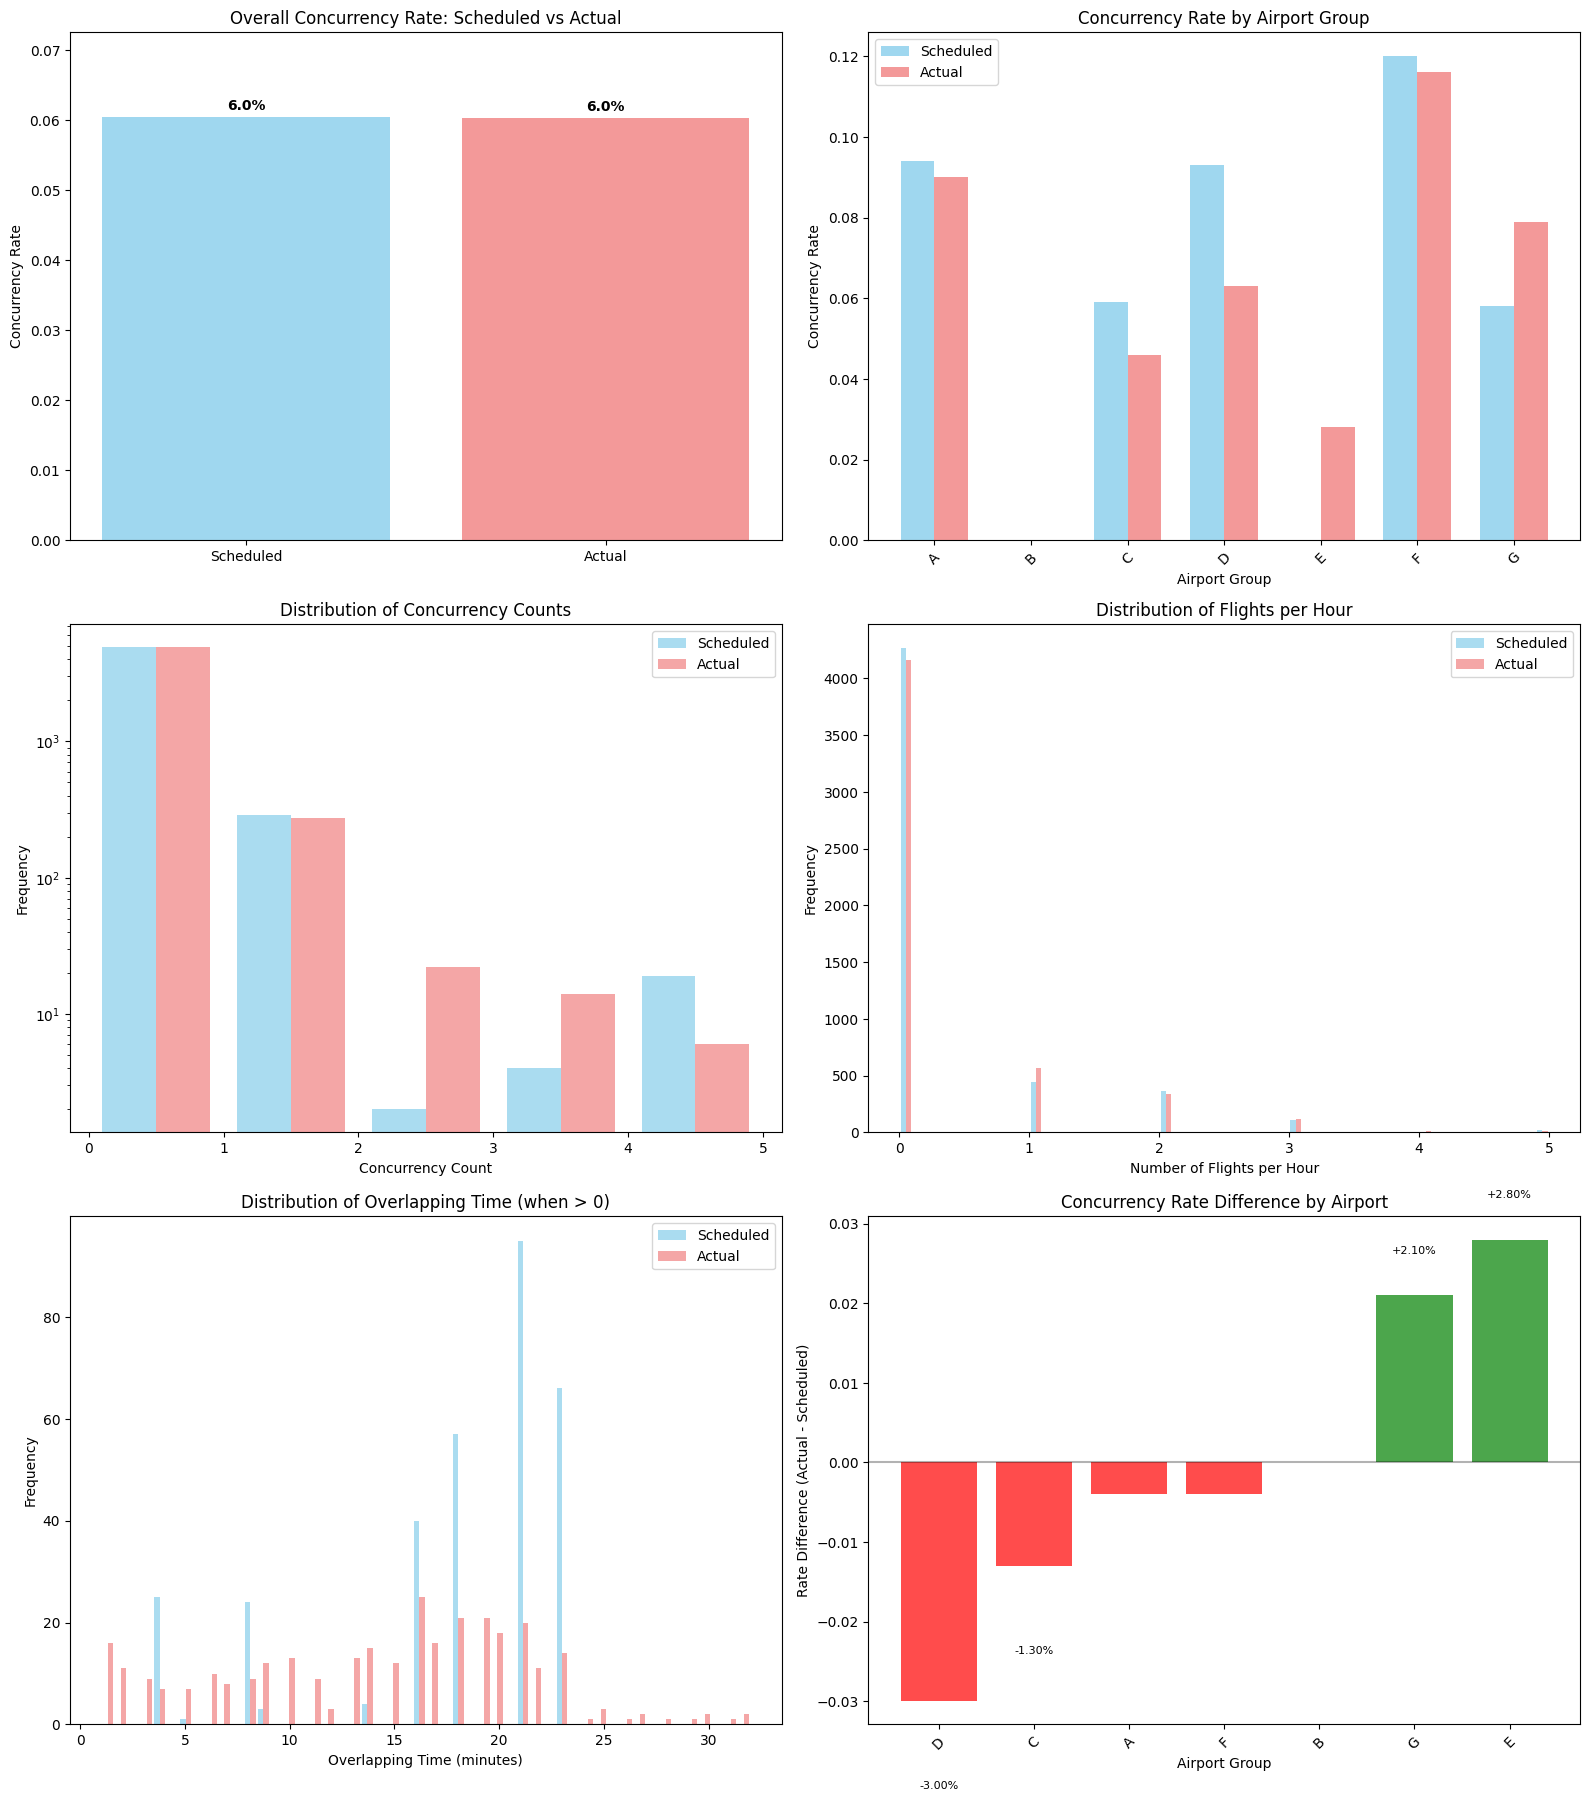

In [4]:
# Create comprehensive visualizations
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Overall concurrency rate comparison
datasets = ["Scheduled", "Actual"]
rates_oct = [
    scheduled_df_oct["is_concurrency"].mean(),
    actual_df_oct["is_concurrency"].mean(),
]
colors = ["skyblue", "lightcoral"]

bars_oct = axes[0, 0].bar(datasets, rates_oct, color=colors, alpha=0.8)
axes[0, 0].set_ylabel("Concurrency Rate")
axes[0, 0].set_title("Overall Concurrency Rate: Scheduled vs Actual")
axes[0, 0].set_ylim(0, max(rates_oct) * 1.2)

# Add percentage labels
for bar, rate in zip(bars_oct, rates_oct):
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(rates_oct) * 0.01,
        f"{rate:.1%}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

# 2. Airport-wise concurrency rate comparison
airport_comparison_plot = airport_comparison_oct[["rate_sched", "rate_actual"]].fillna(
    0
)
x_pos = range(len(airport_comparison_plot))
width = 0.35

axes[0, 1].bar(
    [x - width / 2 for x in x_pos],
    airport_comparison_plot["rate_sched"],
    width,
    label="Scheduled",
    color="skyblue",
    alpha=0.8,
)
axes[0, 1].bar(
    [x + width / 2 for x in x_pos],
    airport_comparison_plot["rate_actual"],
    width,
    label="Actual",
    color="lightcoral",
    alpha=0.8,
)

axes[0, 1].set_xlabel("Airport Group")
axes[0, 1].set_ylabel("Concurrency Rate")
axes[0, 1].set_title("Concurrency Rate by Airport Group")
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(airport_comparison_plot.index)
axes[0, 1].legend()
axes[0, 1].tick_params(axis="x", rotation=45)

# 3. Concurrency count distribution
combined_df = pd.concat([scheduled_df_oct, actual_df_oct])

axes[1, 0].hist(
    [scheduled_df_oct["concurrency"], actual_df_oct["concurrency"]],
    bins=range(0, max(combined_df["concurrency"]) + 2),
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[1, 0].set_xlabel("Concurrency Count")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].set_title("Distribution of Concurrency Counts")
axes[1, 0].legend()
axes[1, 0].set_yscale("log")  # Log scale due to potentially large differences

# 4. Number of flights distribution
axes[1, 1].hist(
    [scheduled_df_oct["number_of_flights"], actual_df_oct["number_of_flights"]],
    bins=50,
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[1, 1].set_xlabel("Number of Flights per Hour")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].set_title("Distribution of Flights per Hour")
axes[1, 1].legend()

# 5. Overlapping time comparison
axes[2, 0].hist(
    [
        scheduled_df_oct[scheduled_df_oct["overlapping_time_minutes"] > 0][
            "overlapping_time_minutes"
        ],
        actual_df_oct[actual_df_oct["overlapping_time_minutes"] > 0][
            "overlapping_time_minutes"
        ],
    ],
    bins=50,
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[2, 0].set_xlabel("Overlapping Time (minutes)")
axes[2, 0].set_ylabel("Frequency")
axes[2, 0].set_title("Distribution of Overlapping Time (when > 0)")
axes[2, 0].legend()

# 6. Rate difference by airport group
rate_diff_oct = airport_comparison_oct["rate_difference"].fillna(0).sort_values()
colors_diff = ["red" if x < 0 else "green" for x in rate_diff_oct]

bars_diff_oct = axes[2, 1].bar(
    range(len(rate_diff_oct)), rate_diff_oct, color=colors_diff, alpha=0.7
)
axes[2, 1].set_xlabel("Airport Group")
axes[2, 1].set_ylabel("Rate Difference (Actual - Scheduled)")
axes[2, 1].set_title("Concurrency Rate Difference by Airport")
axes[2, 1].set_xticks(range(len(rate_diff_oct)))
axes[2, 1].set_xticklabels(rate_diff_oct.index, rotation=45)
axes[2, 1].axhline(y=0, color="black", linestyle="-", alpha=0.3)

# Add value labels for significant differences
for i, (bar, val) in enumerate(zip(bars_diff_oct, rate_diff_oct)):
    if abs(val) > 0.01:  # Only label significant differences
        axes[2, 1].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (0.005 if val > 0 else -0.01),
            f"{val:+.2%}",
            ha="center",
            va="bottom" if val > 0 else "top",
            fontsize=8,
        )

plt.tight_layout()
plt.show()


⏰ TIME-BASED PATTERN ANALYSIS:

Common time periods for correlation analysis: 5,208


/tmp/ipykernel_1032240/2707406685.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  scheduled_df_oct["datetime"] = pd.to_datetime(
/tmp/ipykernel_1032240/2707406685.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  actual_df_oct["datetime"] = pd.to_datetime(
/tmp/ipykernel_1032240/2707406685.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydat

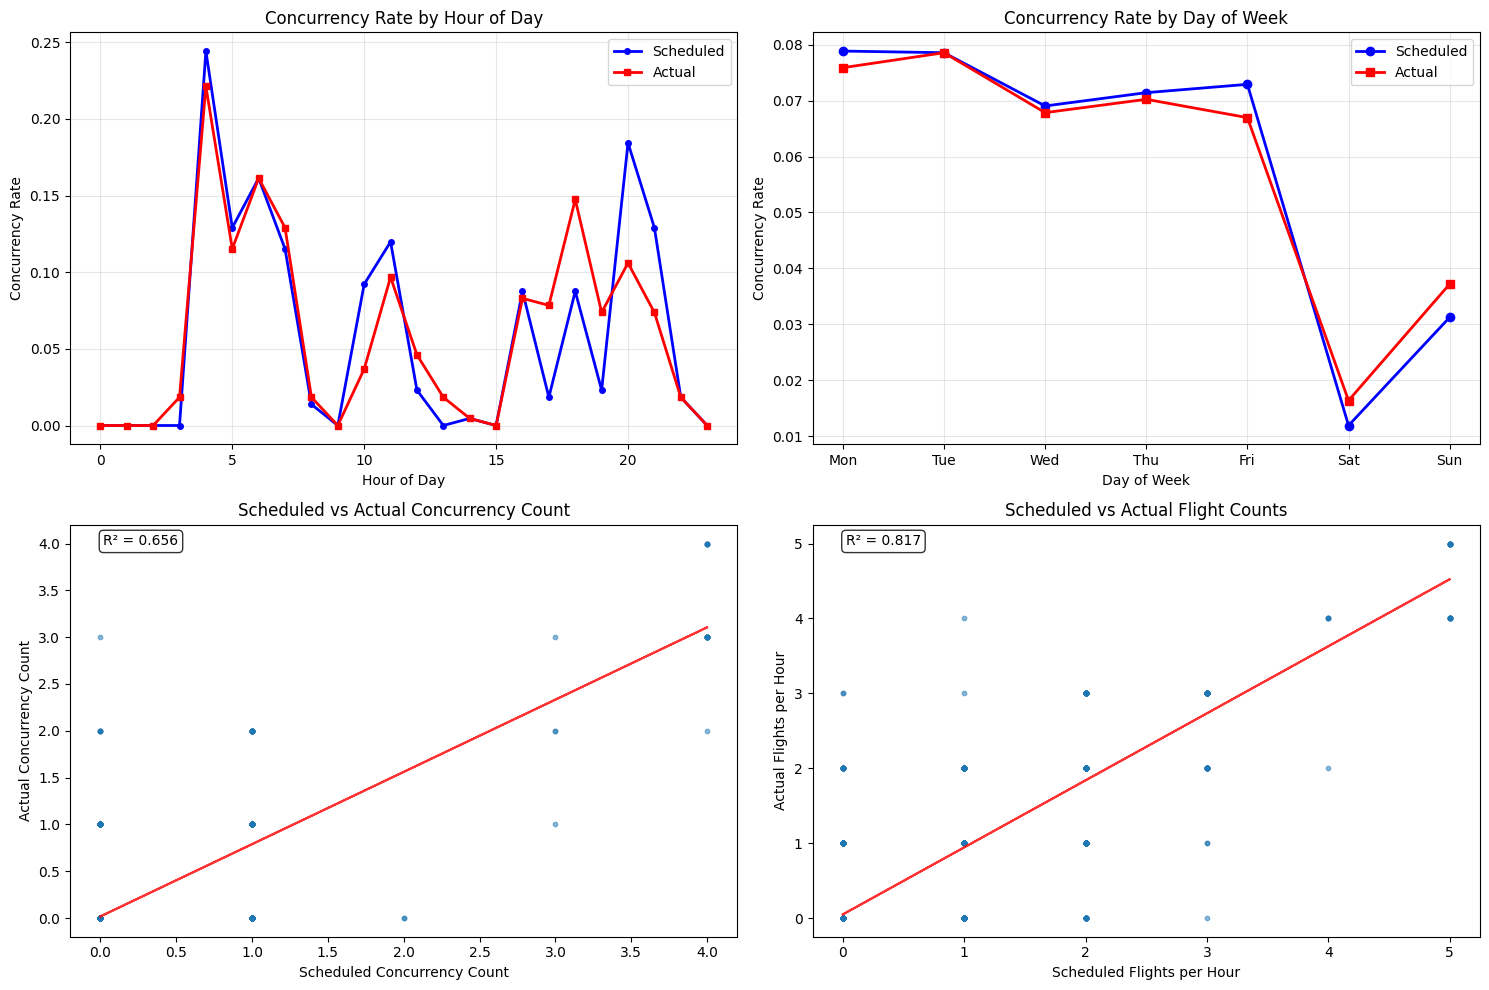


📈 CORRELATION ANALYSIS:
• Concurrency count correlation: 0.810
• Flight count correlation: 0.904
• Binary concurrency correlation: 0.734


In [5]:
# Time-based analysis
print("\n⏰ TIME-BASED PATTERN ANALYSIS:")

# Convert date columns to datetime for both datasets
scheduled_df_oct["datetime"] = pd.to_datetime(
    scheduled_df_oct["date"].astype(str)
    + " "
    + scheduled_df_oct["hour"].astype(str)
    + ":00:00"
)
actual_df_oct["datetime"] = pd.to_datetime(
    actual_df_oct["date"].astype(str)
    + " "
    + actual_df_oct["hour"].astype(str)
    + ":00:00"
)

# Hourly patterns
scheduled_hourly = scheduled_df_oct.groupby("hour")["is_concurrency"].mean()
actual_hourly = actual_df_oct.groupby("hour")["is_concurrency"].mean()

# Daily patterns (day of week)
scheduled_df_oct["day_of_week"] = scheduled_df_oct["datetime"].dt.dayofweek
actual_df_oct["day_of_week"] = actual_df_oct["datetime"].dt.dayofweek

scheduled_daily = scheduled_df_oct.groupby("day_of_week")["is_concurrency"].mean()
actual_daily = actual_df_oct.groupby("day_of_week")["is_concurrency"].mean()

# Plot time patterns
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Hourly pattern
axes[0, 0].plot(
    scheduled_hourly.index,
    scheduled_hourly.values,
    "b-o",
    label="Scheduled",
    linewidth=2,
    markersize=4,
)
axes[0, 0].plot(
    actual_hourly.index,
    actual_hourly.values,
    "r-s",
    label="Actual",
    linewidth=2,
    markersize=4,
)
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Concurrency Rate")
axes[0, 0].set_title("Concurrency Rate by Hour of Day")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Daily pattern
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axes[0, 1].plot(
    scheduled_daily.index,
    scheduled_daily.values,
    "b-o",
    label="Scheduled",
    linewidth=2,
    markersize=6,
)
axes[0, 1].plot(
    actual_daily.index,
    actual_daily.values,
    "r-s",
    label="Actual",
    linewidth=2,
    markersize=6,
)
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_ylabel("Concurrency Rate")
axes[0, 1].set_title("Concurrency Rate by Day of Week")
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(day_names)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Correlation analysis between scheduled and actual
# Merge datasets on common time periods
merge_cols = ["airport_group", "date", "hour"]
comparison_df_oct = pd.merge(
    scheduled_df_oct[
        merge_cols + ["concurrency", "is_concurrency", "number_of_flights"]
    ],
    actual_df_oct[merge_cols + ["concurrency", "is_concurrency", "number_of_flights"]],
    on=merge_cols,
    suffixes=("_sched", "_actual"),
    how="inner",
)

print(f"\nCommon time periods for correlation analysis: {len(comparison_df_oct):,}")

# Correlation scatter plots
axes[1, 0].scatter(
    comparison_df_oct["concurrency_sched"],
    comparison_df_oct["concurrency_actual"],
    alpha=0.5,
    s=10,
)
axes[1, 0].set_xlabel("Scheduled Concurrency Count")
axes[1, 0].set_ylabel("Actual Concurrency Count")
axes[1, 0].set_title("Scheduled vs Actual Concurrency Count")

# Add correlation line
from scipy import stats

if len(comparison_df_oct) > 0:
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        comparison_df_oct["concurrency_sched"], comparison_df_oct["concurrency_actual"]
    )
    line = slope * comparison_df_oct["concurrency_sched"] + intercept
    axes[1, 0].plot(comparison_df_oct["concurrency_sched"], line, "r-", alpha=0.8)
    axes[1, 0].text(
        0.05,
        0.95,
        f"R² = {r_value**2:.3f}",
        transform=axes[1, 0].transAxes,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
    )

# Flight count correlation
axes[1, 1].scatter(
    comparison_df_oct["number_of_flights_sched"],
    comparison_df_oct["number_of_flights_actual"],
    alpha=0.5,
    s=10,
)
axes[1, 1].set_xlabel("Scheduled Flights per Hour")
axes[1, 1].set_ylabel("Actual Flights per Hour")
axes[1, 1].set_title("Scheduled vs Actual Flight Counts")

if len(comparison_df_oct) > 0:
    slope2, intercept2, r_value2, p_value2, std_err2 = stats.linregress(
        comparison_df_oct["number_of_flights_sched"],
        comparison_df_oct["number_of_flights_actual"],
    )
    line2 = slope2 * comparison_df_oct["number_of_flights_sched"] + intercept2
    axes[1, 1].plot(
        comparison_df_oct["number_of_flights_sched"], line2, "r-", alpha=0.8
    )
    axes[1, 1].text(
        0.05,
        0.95,
        f"R² = {r_value2**2:.3f}",
        transform=axes[1, 1].transAxes,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
    )

plt.tight_layout()
plt.show()

# Print correlation statistics
if len(comparison_df_oct) > 0:
    concurrency_corr = comparison_df_oct["concurrency_sched"].corr(
        comparison_df_oct["concurrency_actual"]
    )
    flights_corr = comparison_df_oct["number_of_flights_sched"].corr(
        comparison_df_oct["number_of_flights_actual"]
    )
    binary_corr = comparison_df_oct["is_concurrency_sched"].corr(
        comparison_df_oct["is_concurrency_actual"]
    )

    print(f"\n📈 CORRELATION ANALYSIS:")
    print(f"• Concurrency count correlation: {concurrency_corr:.3f}")
    print(f"• Flight count correlation: {flights_corr:.3f}")
    print(f"• Binary concurrency correlation: {binary_corr:.3f}")

In [6]:
# Final insights and recommendations
print("\n🎯 KEY INSIGHTS AND RECOMMENDATIONS:")
print("=" * 60)

# Calculate key metrics
if len(comparison_df_oct) > 0:
    # Agreement analysis
    perfect_agreement = (
        comparison_df_oct["is_concurrency_sched"]
        == comparison_df_oct["is_concurrency_actual"]
    ).mean()

    # Confusion matrix style analysis
    tp = (
        (comparison_df_oct["is_concurrency_sched"] == 1)
        & (comparison_df_oct["is_concurrency_actual"] == 1)
    ).sum()
    fp = (
        (comparison_df_oct["is_concurrency_sched"] == 1)
        & (comparison_df_oct["is_concurrency_actual"] == 0)
    ).sum()
    tn = (
        (comparison_df_oct["is_concurrency_sched"] == 0)
        & (comparison_df_oct["is_concurrency_actual"] == 0)
    ).sum()
    fn = (
        (comparison_df_oct["is_concurrency_sched"] == 0)
        & (comparison_df_oct["is_concurrency_actual"] == 1)
    ).sum()

    print(f"Confusion Matrix:")
    print(f"• True Positives: {tp}")
    print(f"• False Positives: {fp}")
    print(f"• True Negatives: {tn}")
    print(f"• False Negatives: {fn}")

    total = tp + fp + tn + fn

    if total > 0:
        accuracy = (tp + tn) / total
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = (
            2 * (precision * recall) / (precision + recall)
            if (precision + recall) > 0
            else 0
        )

        print(f"\n📊 PREDICTION PERFORMANCE:")
        print(f"• Schedule accuracy in predicting actual concurrency: {accuracy:.1%}")
        print(
            f"• Precision (when schedule predicts concurrency, how often it's right): {precision:.1%}"
        )
        print(
            f"• Recall (of actual concurrency events, how many were predicted): {recall:.1%}"
        )
        print(f"• F1-Score: {f1:.3f}")

        print(f"\n🔍 DETAILED BREAKDOWN:")
        print(f"• True Positives (correctly predicted concurrency): {tp:,}")
        print(f"• False Positives (predicted concurrency, but none occurred): {fp:,}")
        print(f"• True Negatives (correctly predicted no concurrency): {tn:,}")
        print(f"• False Negatives (missed actual concurrency): {fn:,}")

# Business insights
print(f"\n💼 BUSINESS IMPLICATIONS:")

if "rate_difference" in locals():
    avg_rate_diff = airport_comparison["rate_difference"].mean()
    if avg_rate_diff > 0.05:
        print(
            f"• ⚠️  Actual concurrency is significantly higher than scheduled (+{avg_rate_diff:.1%} on average)"
        )
        print("• This suggests schedules are too optimistic about airport capacity")
        print(
            "• Recommendation: Add buffer time or reduce scheduled flights during peak hours"
        )
    elif avg_rate_diff < -0.05:
        print(
            f"• ✅ Actual concurrency is lower than scheduled ({avg_rate_diff:.1%} on average)"
        )
        print("• This suggests conservative scheduling with room for optimization")
        print("• Recommendation: Consider increasing capacity utilization")
    else:
        print(
            f"• ✅ Actual concurrency closely matches scheduled ({avg_rate_diff:+.1%} difference)"
        )
        print("• This indicates good schedule planning accuracy")

print(f"\n🎯 ACTIONABLE RECOMMENDATIONS:")
print("1. **Real-time Monitoring**: Use actual data to adjust schedules dynamically")
print(
    "2. **Airport-specific Strategies**: Focus on airports with largest scheduled vs actual differences"
)
print(
    "3. **Peak Hour Management**: Implement special procedures during high-concurrency hours"
)
print(
    "4. **Predictive Modeling**: Use these patterns to improve future schedule planning"
)
print(
    "5. **Resource Allocation**: Pre-position resources at airports with high actual concurrency"
)

# Create summary statistics table
summary_stats = pd.DataFrame(
    {
        "Metric": [
            "Total Hours",
            "Hours with Concurrency",
            "Concurrency Rate",
            "Avg Flights/Hour",
            "Max Concurrency",
            "Avg Overlap Time (min)",
        ],
        "Scheduled": [
            f"{len(scheduled_df_oct):,}",
            f"{scheduled_df_oct['is_concurrency'].sum():,}",
            f"{scheduled_df_oct['is_concurrency'].mean():.2%}",
            f"{scheduled_df_oct['number_of_flights'].mean():.1f}",
            f"{scheduled_df_oct['concurrency'].max()}",
            f"{scheduled_df_oct[scheduled_df_oct['overlapping_time_minutes']>0]['overlapping_time_minutes'].mean():.1f}",
        ],
        "Actual": [
            f"{len(actual_df_oct):,}",
            f"{actual_df_oct['is_concurrency'].sum():,}",
            f"{actual_df_oct['is_concurrency'].mean():.2%}",
            f"{actual_df_oct['number_of_flights'].mean():.1f}",
            f"{actual_df_oct['concurrency'].max()}",
            f"{actual_df_oct[actual_df_oct['overlapping_time_minutes']>0]['overlapping_time_minutes'].mean():.1f}",
        ],
    }
)

print(f"\n📋 SUMMARY COMPARISON TABLE:")
print(summary_stats.to_string(index=False))

print(f"\n✅ Analysis complete! The datasets have been thoroughly compared.")


🎯 KEY INSIGHTS AND RECOMMENDATIONS:
Confusion Matrix:
• True Positives: 236
• False Positives: 79
• True Negatives: 4815
• False Negatives: 78

📊 PREDICTION PERFORMANCE:
• Schedule accuracy in predicting actual concurrency: 97.0%
• Precision (when schedule predicts concurrency, how often it's right): 74.9%
• Recall (of actual concurrency events, how many were predicted): 75.2%
• F1-Score: 0.750

🔍 DETAILED BREAKDOWN:
• True Positives (correctly predicted concurrency): 236
• False Positives (predicted concurrency, but none occurred): 79
• True Negatives (correctly predicted no concurrency): 4,815
• False Negatives (missed actual concurrency): 78

💼 BUSINESS IMPLICATIONS:

🎯 ACTIONABLE RECOMMENDATIONS:
1. **Real-time Monitoring**: Use actual data to adjust schedules dynamically
2. **Airport-specific Strategies**: Focus on airports with largest scheduled vs actual differences
3. **Peak Hour Management**: Implement special procedures during high-concurrency hours
4. **Predictive Modeling*